# TP2 - Procesamiento de archivos PDF
**Materia:** Procesamiento del Habla  
**Alumno:** Agustín Delgado

**Documento elegido:** *The agentic AI landscape and its conceptual foundations* (OCDE, 2026). Lo elegí porque trata sobre agentes inteligentes, un tema relacionado con el libro de Russell y Norvig que estoy leyendo.

## 1. Descarga y metadatos
Descargo el informe desde la página oficial de la OCDE y consulto sus propiedades con PyMuPDF.

In [1]:
%pip -q install "pillow<13" pymupdf pdfplumber nltk

import requests
import pymupdf as fitz
import pdfplumber
import pandas as pd
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import RegexpTokenizer
from nltk.corpus import stopwords

url = "https://www.oecd.org/content/dam/oecd/en/publications/reports/2026/02/the-agentic-ai-landscape-and-its-conceptual-foundations_a9d4b451/396cf758-en.pdf"
archivo = "informe_ocde_2026.pdf"
respuesta = requests.get(url, timeout=90, headers={"User-Agent": "Mozilla/5.0"})
respuesta.raise_for_status()
assert respuesta.content.startswith(b"%PDF"), "El archivo descargado no es un PDF"

with open(archivo, "wb") as f:
    f.write(respuesta.content)

documento = fitz.open(archivo)
metadatos = documento.metadata
print("Título:", metadatos.get("title") or "No informado")
print("Autor:", metadatos.get("author") or "No informado en los metadatos")
print("Páginas:", len(documento))
print("Software creador:", metadatos.get("creator") or "No informado")
print("Software productor:", metadatos.get("producer") or "No informado")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 49.3 MB/s eta 0:00:00
Título: The agentic AI landscape and its conceptual foundations (EN)
Autor: OECD
Páginas: 34
Software creador: OECD Publishing Systems
Software productor: PDFsharp 6.2.4 (Original: GPL Ghostscript 9.27)


**Observación:** el informe fue elaborado por Luis Aranda y Kasumi Sugimoto, según sus agradecimientos. Estos nombres pueden no coincidir con el campo «Autor» que guarda internamente el PDF. El archivo contiene 34 páginas con texto seleccionable.

## 2. Extracción y separadores
Para obtener el texto tal como lo entrega la librería utilizo `get_text("text")`. Con `repr()` se ven los saltos de línea sin interpretarlos.

In [2]:
texto_crudo = documento[8].get_text("text", sort=False)
print(repr(texto_crudo[:700]))

separadores = {
    r"\n": texto_crudo.count("\n"),
    r"\r": texto_crudo.count("\r"),
    r"\t": texto_crudo.count("\t"),
    r"\n\n": texto_crudo.count("\n\n"),
    "doble espacio": texto_crudo.count("  ")
}
print("\nSeparadores encontrados:")
for nombre, cantidad in separadores.items():
    print(nombre, ":", cantidad)

'8 \uf07c   \nTHE AGENTIC AI LANDSCAPE AND ITS CONCEPTUAL FOUNDATIONS © OECD 2026 \n  \nThe field of artificial intelligence (AI) is advancing rapidly, with many systems currently designed only to \nreact on demand to human queries with information for humans to consider. However, there is growing \ninterest in AI systems that function more like autonomous agents, capable of pursuing goals, making \ndecisions, and taking actions with minimal human intervention across a wider range of tasks. These \nemerging AI agents and agentic AI systems hold the potential to drive innovation, attract investment, and \nimprove productivity across multiple sectors by streamlining processes and enabling more efficient \nop'

Separadores encontrados:
\n : 29
\r : 0
\t : 0
\n\n : 0
doble espacio : 2


**Análisis:** en este informe las líneas suelen separarse con `\n`, pero ese salto también aparece dentro de un mismo párrafo por el diseño de la página. Un bloque puede tener varios renglones seguidos y no siempre hay un `\n\n` entre párrafos. Las secciones se distinguen sobre todo por sus títulos, la tipografía y los espacios de la página; no por un carácter de «capítulo». La salida muestra si también aparecen `\r`, `\t` o espacios dobles.

## 3. Extracción de una tabla
Tomo la tabla 4.1 de la página 27, sobre usos y herramientas de agentes de IA. Utilizo `pdfplumber` y limpio el resultado en pandas.

In [3]:
with pdfplumber.open(archivo) as pdf:
    pagina = pdf.pages[27]
    region = pagina.crop((pagina.width * .10, pagina.height * .55,
                          pagina.width * .94, pagina.height * .76))
    tabla = region.extract_table(table_settings={
        "vertical_strategy": "explicit",
        "explicit_vertical_lines": [pagina.width * .108, pagina.width * .420, pagina.width * .933],
        "horizontal_strategy": "lines",
        "intersection_tolerance": 8
    })

assert tabla is not None and len(tabla) >= 4, "No se detectó la tabla de la página 27"
filas = [[(valor or "").replace("\n", " ").strip() for valor in fila[:2]]
         for fila in tabla if len(fila) >= 2]
if "use case" in filas[0][0].lower():
    filas = filas[1:]

df_tabla = pd.DataFrame(filas, columns=["Caso de uso", "Herramientas populares"])
df_tabla = df_tabla.replace(r"^\s*$", pd.NA, regex=True).dropna(how="all")
df_tabla = df_tabla.dropna(subset=["Caso de uso"]).reset_index(drop=True)
display(df_tabla)

,Caso de uso,Herramientas populares
0,AI agent memory or data management,"Redis, Github MCP Server, Supabase, Chromadb"
1,AI agent orchestration or agent frameworks,"Ollama, Langchain, Langgraph, Vertex AI, Amazo..."
2,"AI agent observability, monitoring or security","Grafana + Prometheus, Sentry, Snyk, New Relic,..."
3,"Out-of-the-box agents, copilots or assistants","ChatGPT, Github Copilot, Google Gemini, Claude..."


**Análisis:** la tabla queda organizada en dos columnas: una indica para qué se utiliza el agente de IA y la otra menciona herramientas relacionadas. Quité los saltos internos y las filas vacías para poder trabajar con pandas.

## 4. Frecuencia de palabras
Uso la página 8, que contiene texto narrativo sin tablas. Como el informe está en inglés, elimino las stop words de ese idioma con NLTK.

agents: 7
agentic: 7
systems: 4
future: 4
across: 3
field: 2
human: 2
growing: 2
innovation: 2
definitions: 2
recent: 2
developments: 2
landscape: 2
support: 2
oecd: 2


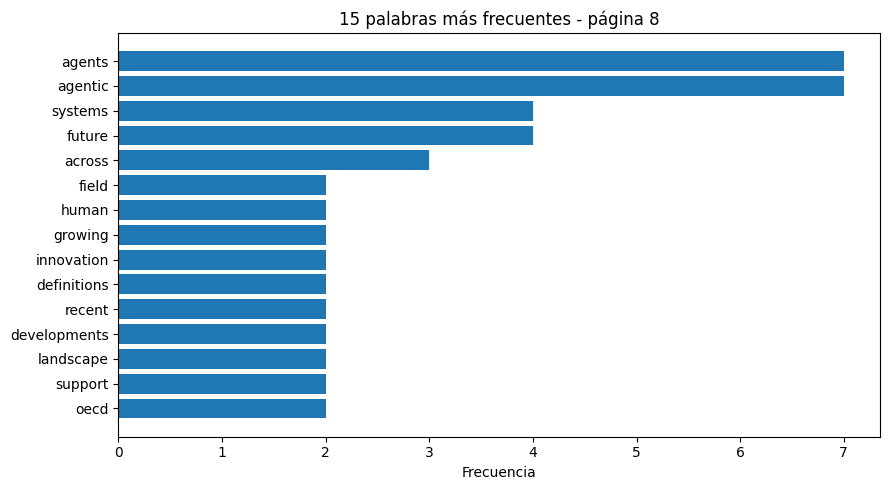

In [4]:
try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = set(stopwords.words("english"))

pagina_texto = documento[8]
texto = pagina_texto.get_text("text", clip=fitz.Rect(55, 160, pagina_texto.rect.width - 55,
                                                      pagina_texto.rect.height - 85))

tokens = RegexpTokenizer(r"[a-z]+").tokenize(texto.lower())
palabras = [palabra for palabra in tokens if palabra not in stop_words and len(palabra) > 2]
frecuencias = Counter(palabras).most_common(15)

for palabra, frecuencia in frecuencias:
    print(f"{palabra}: {frecuencia}")

etiquetas, valores = zip(*reversed(frecuencias))
plt.figure(figsize=(9, 5))
plt.barh(etiquetas, valores)
plt.title("15 palabras más frecuentes - página 8")
plt.xlabel("Frecuencia")
plt.tight_layout()
plt.show()

**Análisis:** algunas palabras repetidas, como *AI*, *agents* o *systems*, pueden aparecer entre las más frecuentes. No las quitaría automáticamente: son importantes para entender el tema del documento. En cambio, elementos del encabezado, el pie de página o las referencias podrían excluirse si aparecen, porque no aportan al contenido narrativo.

**Conclusión:** pude pasar un informe PDF a texto, revisar sus separadores, recuperar una tabla y analizar el vocabulario de una página. La parte más difícil fue obtener la tabla, porque su estructura visual no siempre se conserva al extraerla.

## Referencias
- OCDE (2026). *The agentic AI landscape and its conceptual foundations*. [PDF original](https://www.oecd.org/content/dam/oecd/en/publications/reports/2026/02/the-agentic-ai-landscape-and-its-conceptual-foundations_a9d4b451/396cf758-en.pdf). DOI: [10.1787/396cf758-en](https://doi.org/10.1787/396cf758-en).
- Documentación utilizada: [PyMuPDF](https://pymupdf.readthedocs.io/), [pdfplumber](https://github.com/jsvine/pdfplumber), [NLTK](https://www.nltk.org/).
- **Conversación con IA (ChatGPT):** agregar aquí el enlace compartido de esta conversación antes de entregar.